# 04 – Embeddings

Goal: turn job descriptions into vectors so a CV can be matched by meaning, not only by shared words.

1. Try the model on a few sentences.
2. Chunk descriptions (≤ 256 tokens).
3. Embed all chunks of the unique data jobs and save them.
4. Sanity check: do postings of the same role end up close together? (UMAP)
5. Match a sample CV to the nearest postings.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
print("max tokens:", model.max_seq_length)

W1120 16:02:43.712000 15398 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

max tokens: 256


shape: (7, 384)


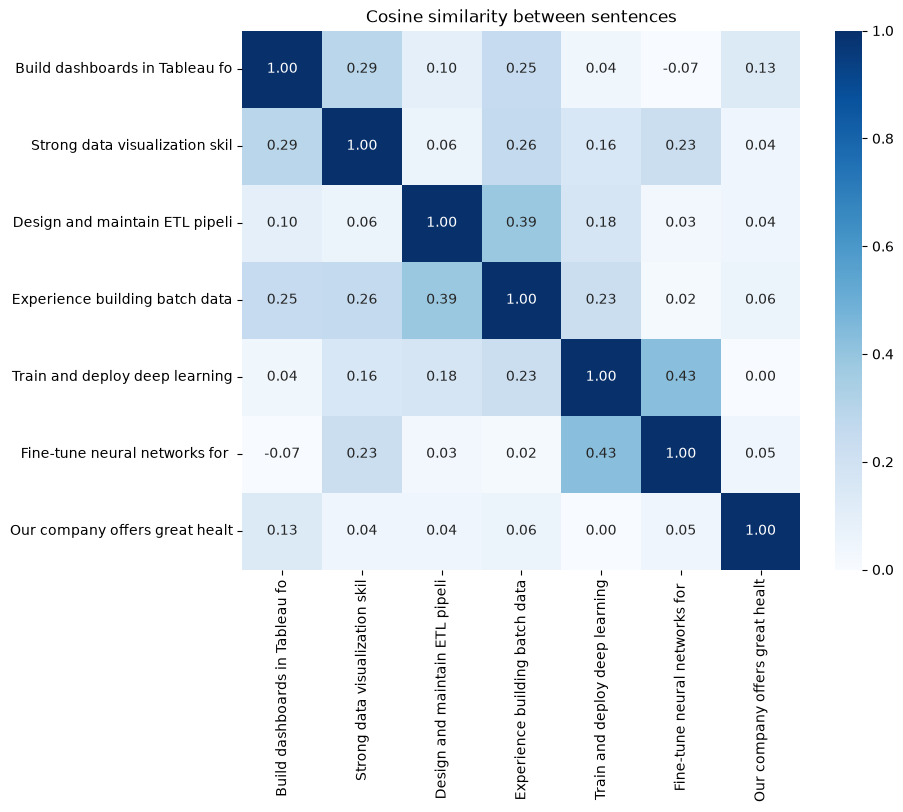

In [2]:
sentences = [
    "Build dashboards in Tableau for senior management",
    "Strong data visualization skills",
    "Design and maintain ETL pipelines with Airflow",
    "Experience building batch data workflows and orchestration",
    "Train and deploy deep learning models with PyTorch",
    "Fine-tune neural networks for computer vision",
    "Our company offers great health benefits and a 401(k)",
]

emb = model.encode(sentences, normalize_embeddings=True)
print("shape:", emb.shape)

sim = emb @ emb.T
labels = [s[:30] for s in sentences]

plt.figure(figsize=(9, 7))
sns.heatmap(pd.DataFrame(sim, index=labels, columns=labels),
            annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Cosine similarity between sentences")
plt.show()

### First test: 7 sentences

- Every paraphrase pair has its highest similarity with its partner (0.29, 0.39, 0.43) without shared words; the company-benefits sentence stays low with all (≤ 0.13).
- Absolute values are low and the visualization pair is only slightly above the next best (0.29 vs 0.26) → only the ranking matters; any threshold must be calibrated for this model.
- MiniLM is small and fast (6 layers); compare with a stronger embedding model in phase 2.

## Step 2: Chunking

In [3]:
import sys
sys.path.append("..")
from src.chunking import load_tokenizer, chunk_text

tok = load_tokenizer()
jobs = (pd.read_parquet("../data/processed/linkedin_data_jobs.parquet")
          .drop_duplicates("desc_group").reset_index(drop=True))

example = jobs.loc[3, "description"]
for i, c in enumerate(chunk_text(example, tok)):
    print(f"--- chunk {i} ({len(tok.encode(c).ids)} tokens)\n{c[:300]}\n")

--- chunk 0 (196 tokens)
Data Engineer with Kafka (W2 Only)💯% Remote Min 10 to12+ strong development experience neededVery strong experience in Kafka and Kafka data injection Strong exp in working with API. Strong exp in Python with AWS. Experience with Informatica IICS and Snowflake. Expertise in Snowflake's cloud data pla



In [4]:
jobs["chunks"] = jobs["description"].apply(lambda d: chunk_text(d, tok))
n_chunks = jobs["chunks"].str.len()
print("postings:", len(jobs), "| chunks:", n_chunks.sum())
print(n_chunks.describe().round(1))

chunk_tokens = jobs["chunks"].explode().apply(lambda c: len(tok.encode(c).ids))
print("\ntokens per chunk (with special tokens):")
print(chunk_tokens.describe().round(0))
print("chunks over 256 tokens:", (chunk_tokens > 256).sum())

postings: 2617 | chunks: 11897
count    2617.0
mean        4.5
std         2.5
min         1.0
25%         2.0
50%         4.0
75%         6.0
max        18.0
Name: chunks, dtype: float64

tokens per chunk (with special tokens):
count    11897.0
mean       167.0
std         42.0
min         15.0
25%        156.0
50%        184.0
75%        195.0
max        220.0
Name: chunks, dtype: float64
chunks over 256 tokens: 0


In [5]:
import textwrap

# A posting with 4 chunks (the median), printed with line wrapping
example = jobs[jobs["chunks"].str.len() == 4].iloc[0]
print(example["title"], "\n")
for i, c in enumerate(example["chunks"]):
    print(f"--- chunk {i} ({len(tok.encode(c).ids)} tokens)")
    print(textwrap.fill(c, width=120), "\n")

Data Science Software Engineer 

--- chunk 0 (185 tokens)
Company Overview Sovrinti is a full-service energy storage system supplier and integrator. Using our core strengths of
expert service to our customers, unparalleled safety, and excellence in manufacturing, we bring standardized, fully
integrated energy storage systems to a rapidly growing worldwide market. Our systems address our customers' needs to
reduce capital equipment and installation costs while enhancing system level performance and reliability using automated
monitoring systems and analytics across the battery, power conditioning and auxiliary systems. Our AEROS® energy
operating system is the engine of innovation to provide advanced control functions allowing our customers to maximize
the value of their energy storage assets. Our service capabilities include advanced monitoring and analytics, scheduled
maintenance, augmentation, and auxiliary system upgrades. The combination of excellence in battery technology and
prod

In [6]:
all_chunks = jobs["chunks"].explode()

tiny = all_chunks[chunk_tokens.values < 20]
print("chunks under 20 tokens:", len(tiny), f"({len(tiny) / len(chunk_tokens):.1%})")
print("chunks containing '##':", all_chunks.str.contains("##", regex=False).sum())

tiny.sample(min(15, len(tiny)), random_state=0).tolist()

chunks under 20 tokens: 1 (0.0%)
chunks containing '##': 0


['Skill Sets: SparkPyspark. TableauSQL Query']

### Chunking results

- 2,617 unique postings → 11,897 chunks (mean 4.5, median 4, max 18 per posting).
- Median chunk 184 tokens, min 15, max 220, 0 chunks over the 256-token limit.
- Units: lines, bullets, sentences (also "end.Next" glued without a space), greedily packed up to 200 tokens.
- Lines longer than 200 tokens are cut into word windows of max 100 tokens (never inside a word, original casing kept). A first version cut them in token windows and decoded them back, which produced broken pieces ("##fs.", "u. S.") and lone headings.
- A last chunk under 20 tokens is merged into the previous one. Only 1 tiny chunk remains (a very short posting).
- Example: in a typical 4-chunk posting the first chunk is only the company intro → for CV matching, the best chunk is a better signal than the mean of all chunks.

## Step 3: Embed all chunks

In [7]:
import time
import torch

device = "mps" if torch.backends.mps.is_available() else "cpu"
model = model.to(device)
print("device:", device)

# One row per chunk, in a fixed order: row i ↔ vector i
chunks = (jobs[["job_id", "desc_group", "title", "role", "level", "chunks"]]
            .explode("chunks")
            .rename(columns={"chunks": "text"})
            .reset_index(drop=True))
chunks["chunk_idx"] = chunks.groupby("job_id").cumcount()
print("chunks to embed:", len(chunks))

start = time.time()
chunk_emb = model.encode(chunks["text"].tolist(), batch_size=64,
                         normalize_embeddings=True, show_progress_bar=True,
                         convert_to_numpy=True)
print(f"shape {chunk_emb.shape} in {time.time() - start:.0f} s")
print("vector lengths (should be 1):", np.linalg.norm(chunk_emb[:5], axis=1).round(3))

device: mps
chunks to embed: 11897


Batches:   0%|          | 0/186 [00:00<?, ?it/s]

shape (11897, 384) in 23 s
vector lengths (should be 1): [1. 1. 1. 1. 1.]


In [9]:
# Mean pooling: one vector per posting = average of its chunk vectors
jobs_meta = (jobs[["job_id", "desc_group", "title", "company_name", "role", "level", "state", "salary"]]
               .reset_index(drop=True))

job_emb = (pd.DataFrame(chunk_emb)
             .groupby(chunks["job_id"].values).mean()
             .loc[jobs_meta["job_id"]]
             .to_numpy(dtype=np.float32))
job_emb = job_emb / np.linalg.norm(job_emb, axis=1, keepdims=True)
print("job vectors:", job_emb.shape)

job vectors: (2617, 384)


In [10]:
from pathlib import Path

OUT = Path("../data/processed")
chunks.to_parquet(OUT / "chunks.parquet", index=False)
np.save(OUT / "chunk_embeddings.npy", chunk_emb)
jobs_meta.to_parquet(OUT / "jobs_meta.parquet", index=False)
np.save(OUT / "job_embeddings.npy", job_emb)

for f in ["chunks.parquet", "chunk_embeddings.npy", "jobs_meta.parquet", "job_embeddings.npy"]:
    print(f, f"{(OUT / f).stat().st_size / 1e6:.1f} MB")

chunks.parquet 5.4 MB
chunk_embeddings.npy 18.3 MB
jobs_meta.parquet 0.1 MB
job_embeddings.npy 4.0 MB


In [11]:
i = 1234
fresh = model.encode([chunks.loc[i, "text"]], normalize_embeddings=True)[0]
print("same chunk, stored vs fresh:", round(float(fresh @ chunk_emb[i]), 4))
print("next chunk (different text):", round(float(fresh @ chunk_emb[i + 1]), 4))

same chunk, stored vs fresh: 1.0
next chunk (different text): 0.6852


### Embedding results

- 11,897 chunks embedded with all-MiniLM-L6-v2 on Apple MPS in 23 s (batch size 64), vectors normalized to length 1.
- Mean pooling (then re-normalized) → one vector per posting: 2,617 × 384.
- Saved to data/processed: chunks.parquet + chunk_embeddings.npy (row i ↔ vector i), jobs_meta.parquet + job_embeddings.npy.
- Spot check: re-embedding a stored chunk gives similarity ≈ 1.0 with its saved vector → rows and vectors are aligned.